In [14]:

import sys
import qiskit
import qiskit_aer
import numpy as np

print("Q-OPTIMA NOTEBOOK INITIALIZED")
print("Python:", sys.version.split()[0])
print("Qiskit:", qiskit.__version__)
print("Aer:", qiskit_aer.__version__)
print("NumPy:", np.__version__)


Q-OPTIMA NOTEBOOK INITIALIZED
Python: 3.12.10
Qiskit: 2.5.2
Aer: 0.17.2
NumPy: 2.5.4



# Q-OPTIMA: Noise-Aware Quantum Simulation and Trotter Optimization

**Qiskit Fall Fest 2026 — Phase 2**

**Track:** Quantum Simulation  
**Problem:** PS-S3 — Noise Accumulation in Trotter Circuits

## 1. Quantum System

We simulate a four-qubit transverse-field Ising model (TFIM) arranged in a ring.

The Hamiltonian is:

$$
H = -J\sum_{(i,j)\in E} Z_iZ_j
    -g\sum_{i=0}^{3}X_i
$$

where:

- $E=\{(0,1),(1,2),(2,3),(3,0)\}$
- $J=g=1$
- Initial state: $|1010\rangle$
- Evolution time: $T=2$
- Method: First-order Trotterization

**Research objective:** Find the Trotter step count that best balances approximation error and accumulated hardware noise.


In [15]:

import sys
from pathlib import Path

from qiskit.quantum_info import Statevector

ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "starter"))

from qff_sim import (
    load_processor,
    tfim_hamiltonian,
    exact_evolution,
    trotter_circuit,
    noisy_state_fidelity,
)

STEPS = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 14, 16]

H = tfim_hamiltonian(
    4,
    J=1.0,
    g=1.0,
    periodic=True
)

initial_state = Statevector.from_label("1010")
exact_state = exact_evolution(H, initial_state, [2.0])[0]

processor_d = load_processor(
    str(ROOT / "processors" / "processor_D.json")
)

print("PASS: Hamiltonian constructed")
print("PASS: Exact quantum evolution calculated")
print("PASS: Processor D loaded")
print("Trotter steps:", STEPS)


PASS: Hamiltonian constructed
PASS: Exact quantum evolution calculated
PASS: Processor D loaded
Trotter steps: [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 14, 16]


In [16]:

ideal_results = []

for n in STEPS:
    qc = trotter_circuit(
        n=4,
        J=1.0,
        g=1.0,
        t=2.0,
        steps=n,
        order=1,
        zz_mode="cx",
        initial_label="1010",
        periodic=True,
    )

    fidelity = noisy_state_fidelity(
        qc,
        exact_state,
        processor_d,
        noisy=False,
    )

    ideal_results.append({
        "steps": n,
        "ideal_fidelity": fidelity,
    })

    print(f"n={n:2d} | Ideal fidelity={fidelity:.6f}")

print("\nPASS: Ideal Trotter scan completed")


n= 1 | Ideal fidelity=0.115037
n= 2 | Ideal fidelity=0.289041
n= 3 | Ideal fidelity=0.065841
n= 4 | Ideal fidelity=0.517567
n= 5 | Ideal fidelity=0.759999
n= 6 | Ideal fidelity=0.864191
n= 7 | Ideal fidelity=0.914448
n= 8 | Ideal fidelity=0.941669
n=10 | Ideal fidelity=0.968139
n=12 | Ideal fidelity=0.979984
n=14 | Ideal fidelity=0.986256
n=16 | Ideal fidelity=0.989970

PASS: Ideal Trotter scan completed



## 2. Noisy Trotter Benchmark

We compare three quantum processor architectures: A, B, and D.

For Processor D, we evaluate noise scales of 0.5×, 1×, and 2×.

Each configuration is evaluated at 12 Trotter step counts, producing 60 benchmark rows.

We record noisy state fidelity, ideal Trotter fidelity, staggered magnetization, statistical uncertainty, and circuit resource costs.


In [17]:

import subprocess
import sys

result = subprocess.run(
    [sys.executable, str(ROOT / "run_s3_benchmark.py")],
    cwd=str(ROOT),
    capture_output=True,
    text=True,
)

print(result.stdout[-5000:])

if result.returncode != 0:
    print(result.stderr[-5000:])
    raise RuntimeError("Benchmark failed")

print("PASS: 60 noisy benchmark experiments reproduced")



=== Processor A ===
A | scale=1.0 | steps= 1 | noisy fidelity=0.110107
A | scale=1.0 | steps= 2 | noisy fidelity=0.261911
A | scale=1.0 | steps= 3 | noisy fidelity=0.068498
A | scale=1.0 | steps= 4 | noisy fidelity=0.404977
A | scale=1.0 | steps= 5 | noisy fidelity=0.546396
A | scale=1.0 | steps= 6 | noisy fidelity=0.577419
A | scale=1.0 | steps= 7 | noisy fidelity=0.569743
A | scale=1.0 | steps= 8 | noisy fidelity=0.548003
A | scale=1.0 | steps=10 | noisy fidelity=0.493125
A | scale=1.0 | steps=12 | noisy fidelity=0.438436
A | scale=1.0 | steps=14 | noisy fidelity=0.388882
A | scale=1.0 | steps=16 | noisy fidelity=0.345239

=== Processor B ===
B | scale=1.0 | steps= 1 | noisy fidelity=0.111160
B | scale=1.0 | steps= 2 | noisy fidelity=0.268853
B | scale=1.0 | steps= 3 | noisy fidelity=0.068147
B | scale=1.0 | steps= 4 | noisy fidelity=0.437500
B | scale=1.0 | steps= 5 | noisy fidelity=0.606539
B | scale=1.0 | steps= 6 | noisy fidelity=0.656538
B | scale=1.0 | steps= 7 | noisy fidelit

In [18]:

import csv

tables = ROOT / "results" / "tables"

expected_rows = {
    "s3_scan.csv": 60,
    "s3_summary.csv": 5,
    "resources.csv": 36,
}

for filename, expected in expected_rows.items():
    with (tables / filename).open(newline="") as f:
        rows = list(csv.DictReader(f))

    assert len(rows) == expected, (
        f"{filename}: expected {expected}, got {len(rows)}"
    )

    print(f"PASS: {filename} — {len(rows)} rows")


PASS: s3_scan.csv — 60 rows
PASS: s3_summary.csv — 5 rows
PASS: resources.csv — 36 rows



## 3. Bell-State Verification

We verify Processor D using two physical-qubit pairs:

- Adjacent pair: (0, 1)
- Nonadjacent pair: (0, 2)

For each pair, we measure XX, YY, and ZZ correlations under ideal and noisy conditions using 4096 shots.

Bell-state fidelity is estimated as:

$$
F_{\mathrm{Bell}}=\frac{1+\langle XX\rangle-\langle YY\rangle+\langle ZZ\rangle}{4}
$$

This experiment evaluates how physical connectivity and noise affect entanglement quality.

## 4. Error Decomposition

We separate the observed total infidelity into:

$$
E_{\mathrm{total}}=1-F_{\mathrm{noisy}}
$$

$$
E_{\mathrm{Trotter}}=1-F_{\mathrm{ideal}}
$$

$$
E_{\mathrm{noise}}=F_{\mathrm{ideal}}-F_{\mathrm{noisy}}
$$

These components satisfy:

$$
E_{\mathrm{total}}=E_{\mathrm{Trotter}}+E_{\mathrm{noise}}
$$

The noise term is an operational difference between fidelities, not a uniquely isolated physical error channel.


In [19]:

import subprocess
import sys

result = subprocess.run(
    [sys.executable, str(ROOT / "run_bell.py")],
    cwd=str(ROOT),
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Bell verification failed")

print("PASS: Bell experiment reproduced")


Testing pair (0, 1) | ideal
Fidelity = 1.000000
Testing pair (0, 1) | noisy
Fidelity = 0.963257
Testing pair (0, 2) | ideal
Fidelity = 1.000000
Testing pair (0, 2) | noisy
Fidelity = 0.954224

PASS: Bell verification completed.
Saved: C:\Users\DHEERAJ KOUSHIK\OneDrive\Desktop\Q-OPTIMA-2026\results\tables\bell.csv

PASS: Bell experiment reproduced


In [20]:

result = subprocess.run(
    [sys.executable, str(ROOT / "error_decomposition.py")],
    cwd=str(ROOT),
    capture_output=True,
    text=True,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Error decomposition failed")

print("PASS: Error decomposition reproduced")


PASS: Error decomposition completed
Rows analyzed: 60
Processor D optimal steps at 1x: 7
Minimum total infidelity: 0.337184
Saved table: C:\Users\DHEERAJ KOUSHIK\OneDrive\Desktop\Q-OPTIMA-2026\results\tables\error_decomposition.csv
Saved graph: C:\Users\DHEERAJ KOUSHIK\OneDrive\Desktop\Q-OPTIMA-2026\results\figures\error_decomposition.png

PASS: Error decomposition reproduced


In [21]:

from pathlib import Path
import csv

required = {
    "bell.csv": 4,
    "error_decomposition.csv": 60,
}

for filename, expected in required.items():
    path = ROOT / "results" / "tables" / filename

    with path.open(newline="") as f:
        rows = list(csv.DictReader(f))

    assert len(rows) == expected, (
        f"{filename}: expected {expected}, got {len(rows)}"
    )

    print(f"PASS: {filename} — {len(rows)} rows")

assert (
    ROOT / "results" / "figures" / "error_decomposition.png"
).exists()

print("PASS: Error decomposition graph exists")


PASS: bell.csv — 4 rows
PASS: error_decomposition.csv — 60 rows
PASS: Error decomposition graph exists



## 5. Q-OPTIMA: Noise-Aware Trotter Advisor

Q-OPTIMA recommends the number of Trotter steps that balances approximation error and accumulated circuit noise.

We evaluate two models:

**Linear model**

$$
\widehat E(n,s)=E_{\mathrm{ideal}}(n)+\alpha_1sn
$$

**Quadratic model**

$$
\widehat E(n,s)=E_{\mathrm{ideal}}(n)+\alpha_2sn^2
$$

Here, $n$ is the number of Trotter steps and $s$ is the noise scale.

Both models are fitted using Processor D data at 1× noise.

We compare their recommendations against simulated optimal step counts.

### Evaluation protocol

The first five noise settings were used during model development. The quadratic model was then frozen and evaluated on five additional noise settings.

The quadratic penalty is an empirical optimization model, not a claim that physical noise necessarily grows quadratically.


In [22]:

import subprocess
import sys

advisor_scripts = [
    "trotter_advisor.py",
    "validate_advisor.py",
    "advisor_v2.py",
    "final_advisor_test.py",
]

for script in advisor_scripts:
    print(f"\nRunning {script}...")

    result = subprocess.run(
        [sys.executable, str(ROOT / script)],
        cwd=str(ROOT),
        capture_output=True,
        text=True,
    )

    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError(f"{script} failed")

    print(result.stdout[-2500:])

print("\nPASS: All advisor experiments reproduced")



Running trotter_advisor.py...
Learned noise coefficient alpha = 0.03285944

Q-OPTIMA ADVISOR RESULTS
----------------------------------------------------------------------
Noise 0.5x | Predicted n=8 | Actual n*=8 | Fidelity regret=0.000000
Noise 1.0x | Predicted n=7 | Actual n*=7 | Fidelity regret=0.000000
Noise 2.0x | Predicted n=6 | Actual n*=6 | Fidelity regret=0.000000

Saved: C:\Users\DHEERAJ KOUSHIK\OneDrive\Desktop\Q-OPTIMA-2026\results\tables\advisor_results.csv


Running validate_advisor.py...
oise 0.25x | n= 1 | F=0.114048
Noise 0.25x | n= 2 | F=0.283809
Noise 0.25x | n= 3 | F=0.066498
Noise 0.25x | n= 4 | F=0.496081
Noise 0.25x | n= 5 | F=0.717967
Noise 0.25x | n= 6 | F=0.806243
Noise 0.25x | n= 7 | F=0.842943
Noise 0.25x | n= 8 | F=0.857845
Noise 0.25x | n=10 | F=0.861598
Noise 0.25x | n=12 | F=0.852155
Noise 0.25x | n=14 | F=0.838041
Noise 0.25x | n=16 | F=0.822068
Noise 0.75x | n= 1 | F=0.112109
Noise 0.75x | n= 2 | F=0.273718
Noise 0.75x | n= 3 | F=0.067647
Noise 0.75x 

In [23]:

import csv
import numpy as np

path = ROOT / "results" / "tables" / "advisor_final_validation.csv"

with path.open(newline="") as f:
    validation = list(csv.DictReader(f))

assert len(validation) == 10

for model in ["linear", "quadratic"]:
    subset = [r for r in validation if r["model"] == model]

    matches = sum(int(r["exact_match"]) for r in subset)
    regret = np.mean([
        float(r["fidelity_regret"]) for r in subset
    ])

    print(
        f"{model:12s} | "
        f"Exact matches: {matches}/5 | "
        f"Mean fidelity regret: {regret:.6f}"
    )

print("\nPASS: Final advisor validation verified")


linear       | Exact matches: 2/5 | Mean fidelity regret: 0.001943
quadratic    | Exact matches: 3/5 | Mean fidelity regret: 0.000422

PASS: Final advisor validation verified



FIGURE: noise_crossover.png


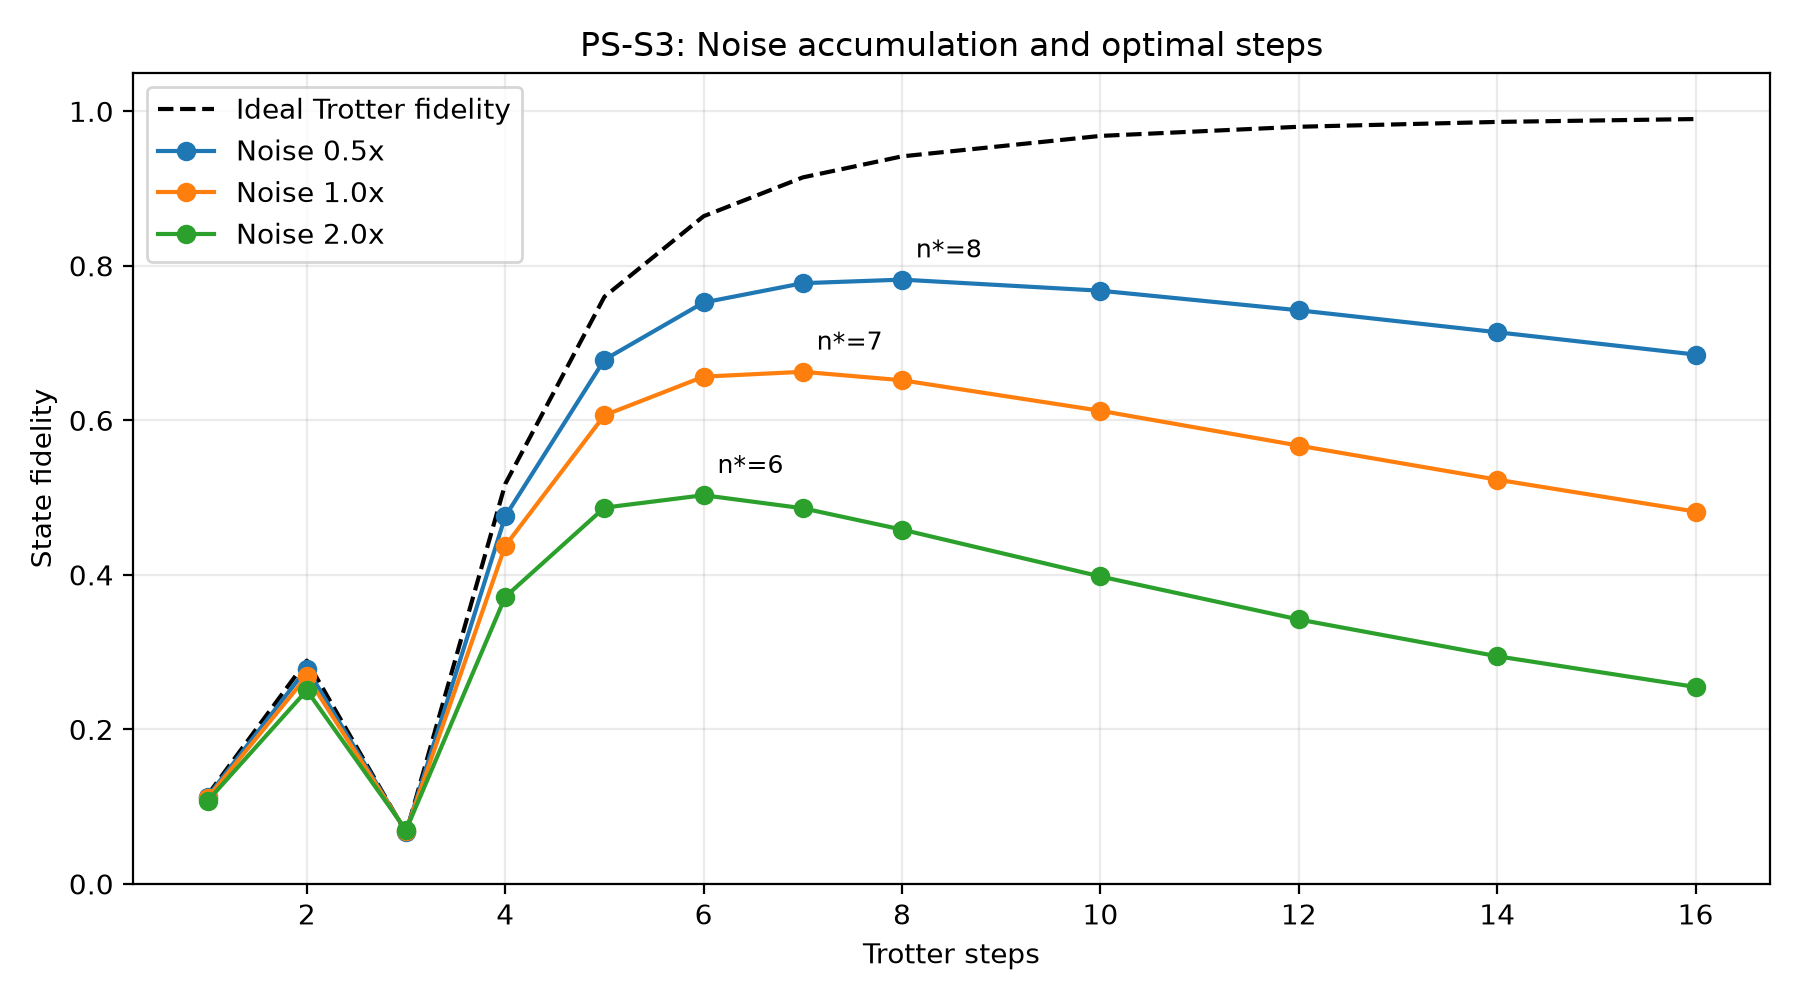


FIGURE: processor_comparison.png


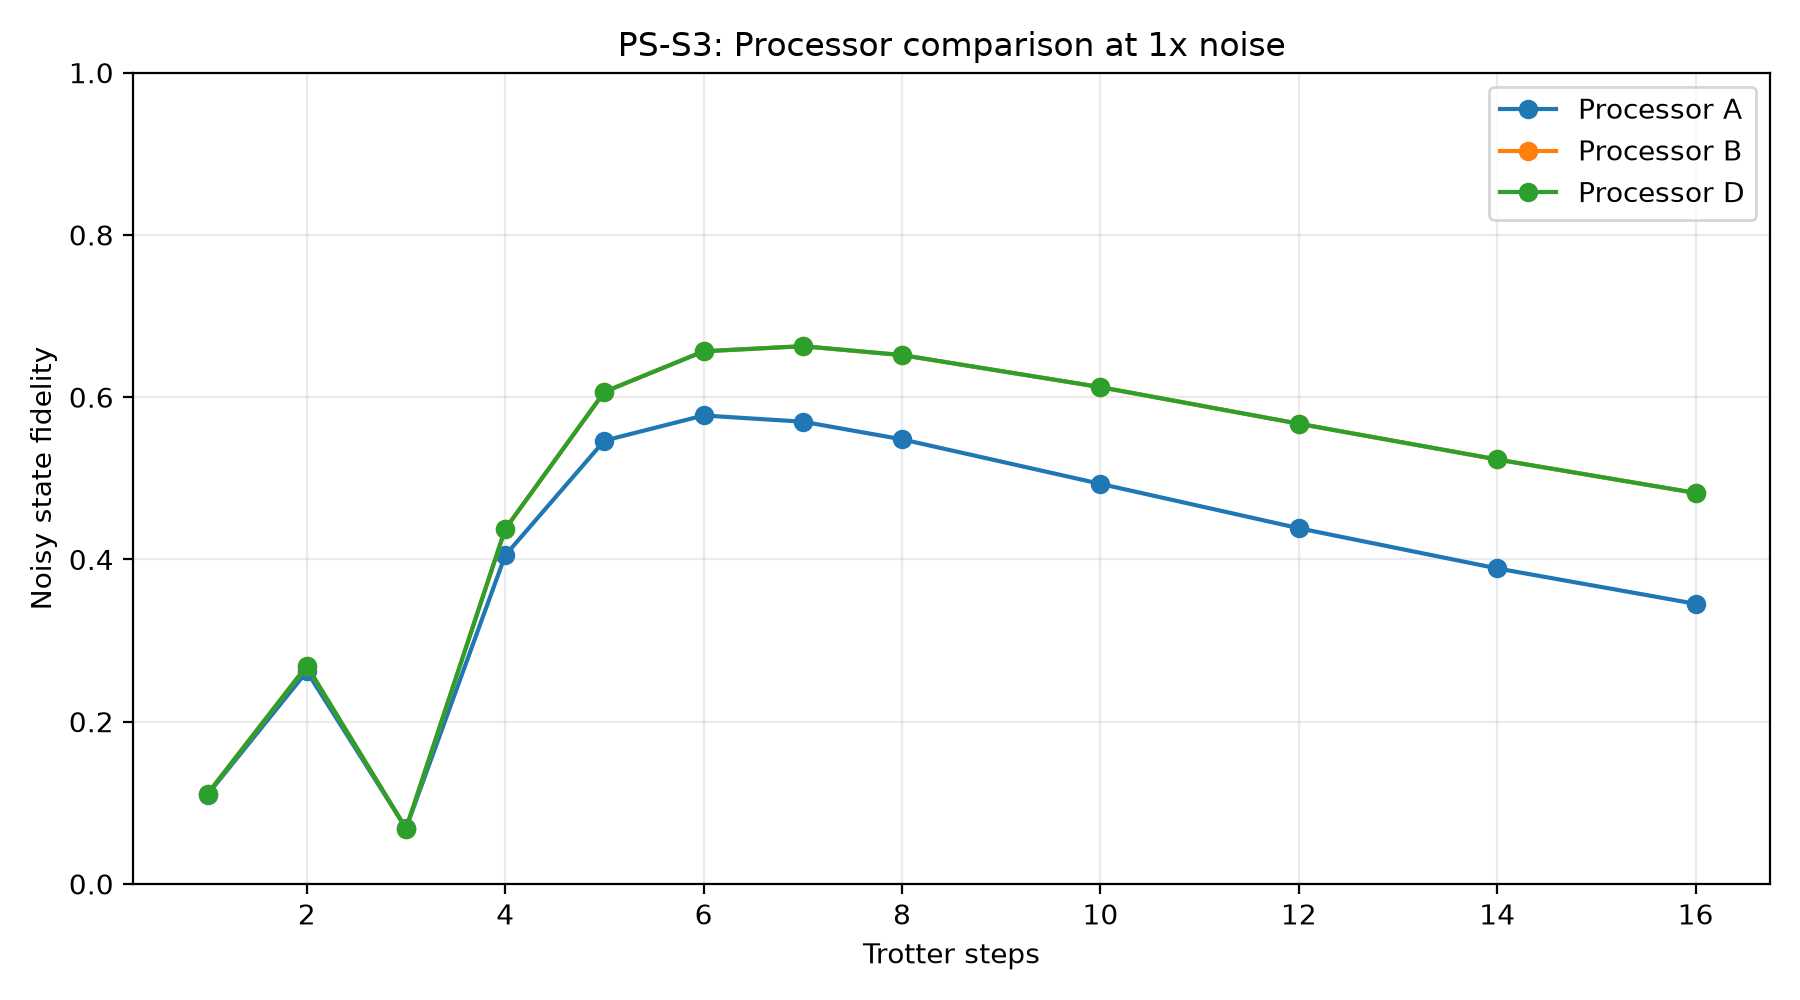


FIGURE: error_decomposition.png


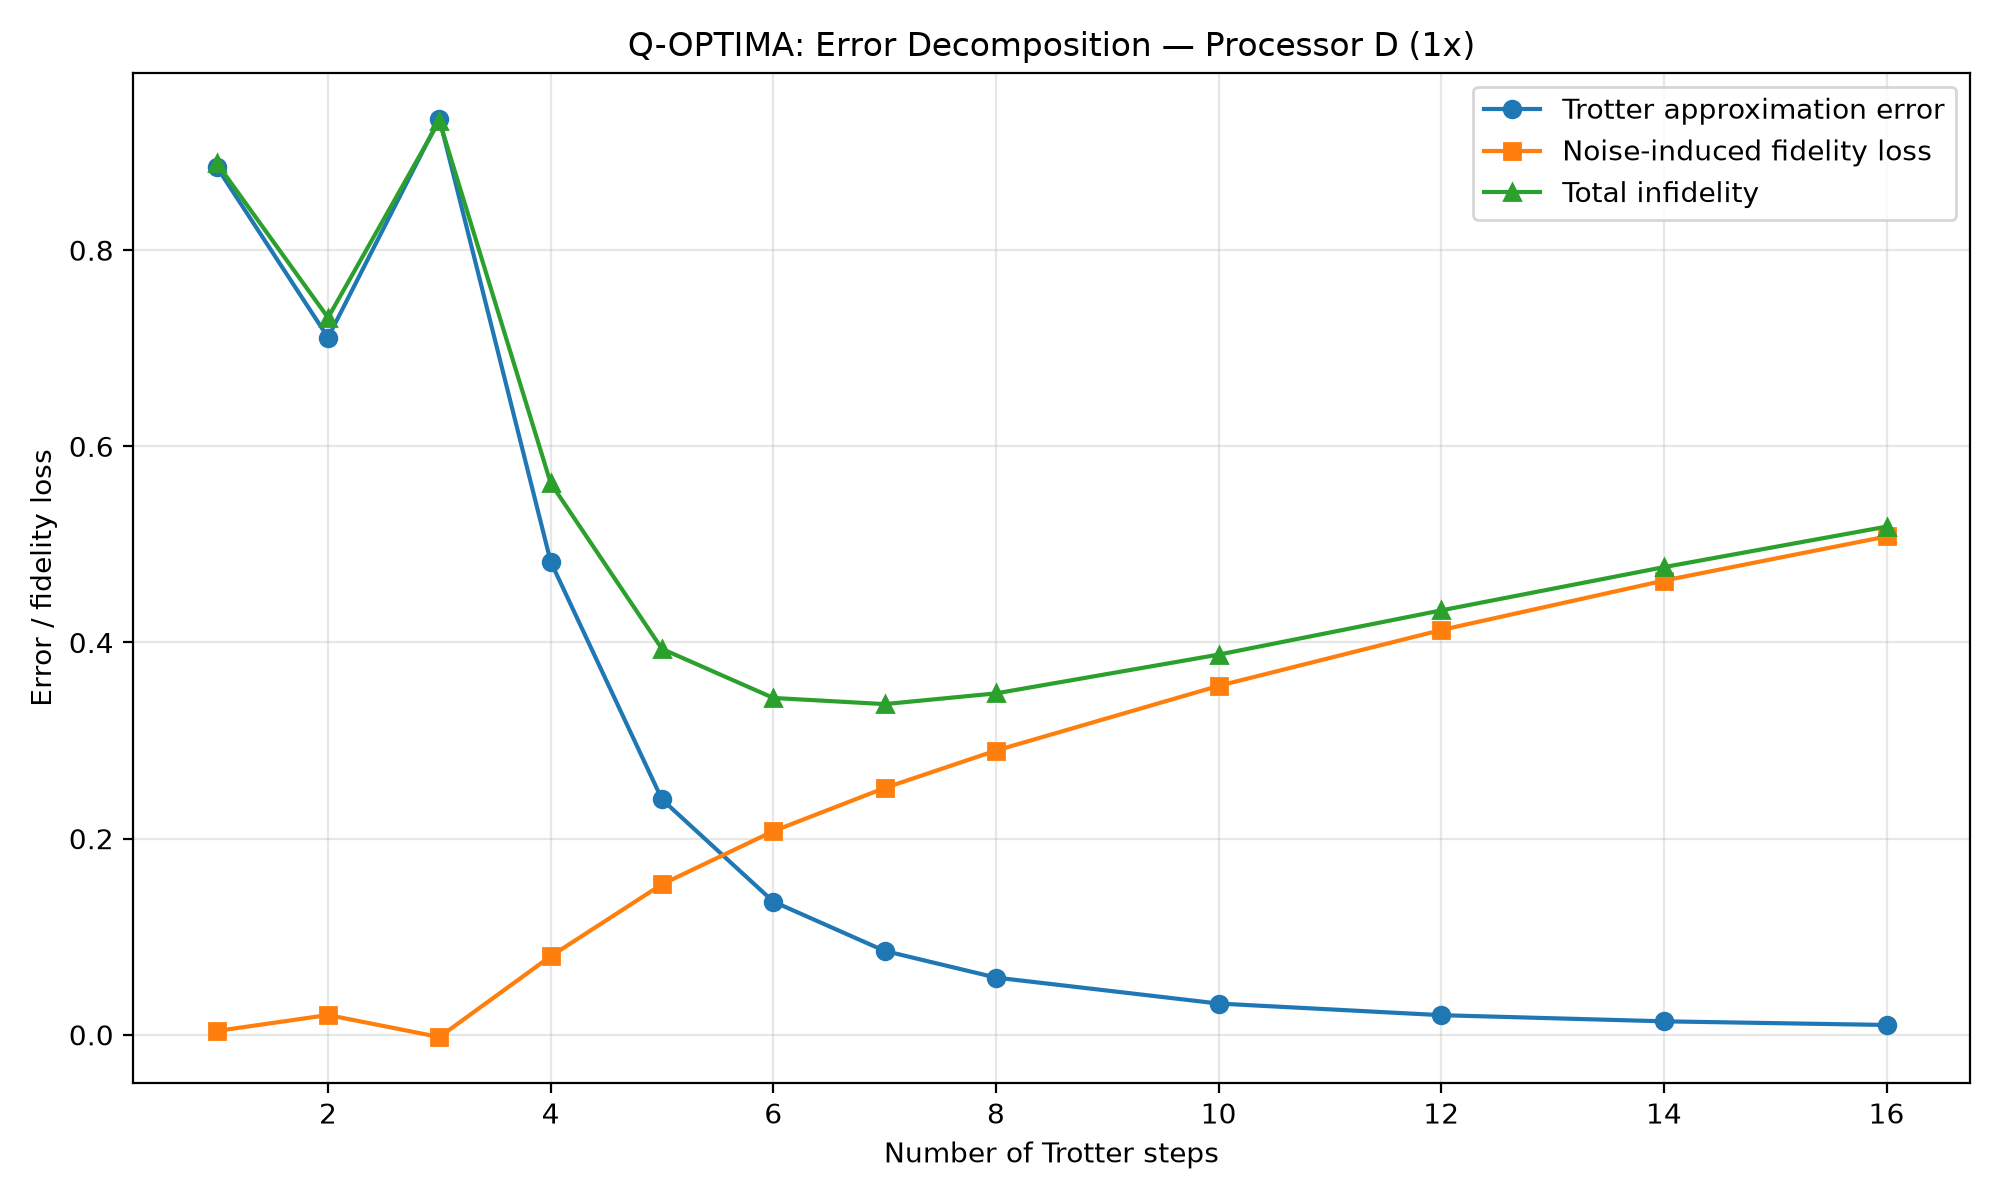


PASS: All research figures displayed


In [24]:

from IPython.display import display, Image
from pathlib import Path

figures = ROOT / "results" / "figures"

figure_files = [
    "noise_crossover.png",
    "processor_comparison.png",
    "error_decomposition.png",
]

for filename in figure_files:
    path = figures / filename
    assert path.exists(), f"Missing figure: {filename}"

    print("\nFIGURE:", filename)
    display(Image(filename=str(path), width=750))

print("\nPASS: All research figures displayed")



## 6. Results and Conclusions

### Key findings

1. **Trotter approximation versus noise:** Increasing the number of Trotter steps generally improves the ideal approximation at sufficiently large step counts, but also increases exposure to hardware noise.

2. **Noise-dependent optimal circuit depth:** For Processor D, the optimal step count decreases as noise increases:
   - 0.5× noise: 8 steps
   - 1× noise: 7 steps
   - 2× noise: 6 steps

3. **Hardware connectivity:** Processor A requires additional routing for the tested circuits, while Processors B and D avoid routing overhead under the selected transpilation settings.

4. **Bell-state verification:** Noisy Bell-state fidelity is lower than ideal fidelity, with the nonadjacent qubit pair showing slightly more degradation.

5. **Q-OPTIMA Advisor:** The quadratic noise-aware advisor achieved 3/5 exact optimal-step matches on five fresh validation settings, compared with 2/5 for the linear baseline.

6. **Fidelity regret:** The quadratic advisor achieved a mean fidelity regret of approximately 0.000422, compared with 0.001943 for the linear advisor, representing approximately 78.3% lower regret on these settings.

### Limitations

- The experiment uses a four-qubit simulation, not physical quantum hardware.
- The advisor is evaluated primarily on Processor D and one Hamiltonian configuration.
- The quadratic noise penalty is empirical and should not be interpreted as a universal physical noise law.
- Additional processors, Hamiltonians, and independent validation settings are needed to establish broader generalization.

### Reproducibility

The notebook uses the official simulation helper, the custom Processor D configuration, and the Python experiment scripts included in this repository.

The simulations were run using Python 3.12.10, Qiskit 2.5.2, and Qiskit Aer 0.17.2.

### AI assistance disclosure

Generative AI assisted with code drafting, debugging, experiment organization, documentation, and interpretation. Numerical results were generated and checked by running the simulation code.



## 7. Fixed-Step Baseline Comparison

We compare the Q-OPTIMA quadratic advisor against a linear advisor and four fixed-step strategies.

Across five fresh validation noise settings, the quadratic advisor achieved:

- 3/5 exact optimal-step matches.
- Mean fidelity regret of 0.000422.
- Approximately 78.3% lower mean regret than the linear advisor.
- Approximately 95.7% lower mean regret than the best tested fixed-step baseline (6 steps).

These findings demonstrate the practical value of noise-aware step selection for the evaluated four-qubit TFIM benchmark.

The results do not establish universal performance across different Hamiltonians, processors, or physical quantum devices.


In [25]:

import subprocess
import sys
import csv
from statistics import mean

result = subprocess.run(
    [sys.executable, str(ROOT / "v2_fixed_step_test.py")],
    cwd=str(ROOT),
    capture_output=True,
    text=True,
)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Fixed-step comparison failed")

print(result.stdout[-1500:])

with (
    ROOT / "results" / "tables" /
    "v2_fixed_step_comparison.csv"
).open(newline="") as f:
    comparison = list(csv.DictReader(f))

assert len(comparison) == 30

for strategy in [
    "quadratic", "linear",
    "fixed_6", "fixed_7", "fixed_8", "fixed_16"
]:
    rows = [
        r for r in comparison
        if r["strategy"] == strategy
    ]

    print(
        f"{strategy:12s} | "
        f"Mean regret: "
        f"{mean(float(r['fidelity_regret']) for r in rows):.6f}"
    )

print("\nPASS: Fixed-step baselines reproduced")


0.497709
Noise 1.25x | n=14 | F=0.450251
Noise 1.25x | n=16 | F=0.407165
Noise 1.8x | n= 1 | F=0.108206
Noise 1.8x | n= 2 | F=0.254047
Noise 1.8x | n= 3 | F=0.069448
Noise 1.8x | n= 4 | F=0.383683
Noise 1.8x | n= 5 | F=0.508577
Noise 1.8x | n= 6 | F=0.530178
Noise 1.8x | n= 7 | F=0.516711
Noise 1.8x | n= 8 | F=0.491257
Noise 1.8x | n=10 | F=0.432594
Noise 1.8x | n=12 | F=0.377083
Noise 1.8x | n=14 | F=0.328526
Noise 1.8x | n=16 | F=0.287052
Noise 2.8x | n= 1 | F=0.104691
Noise 2.8x | n= 2 | F=0.237073
Noise 2.8x | n= 3 | F=0.070536
Noise 2.8x | n= 4 | F=0.327108
Noise 2.8x | n= 5 | F=0.410663
Noise 2.8x | n= 6 | F=0.409626
Noise 2.8x | n= 7 | F=0.383507
Noise 2.8x | n= 8 | F=0.351226
Noise 2.8x | n=10 | F=0.289088
Noise 2.8x | n=12 | F=0.237878
Noise 2.8x | n=14 | F=0.197735
Noise 2.8x | n=16 | F=0.166729

Q-OPTIMA V2 â€” FIXED-STEP BASELINE COMPARISON
linear       | Matches: 2/5 | Mean regret: 0.001943
quadratic    | Matches: 3/5 | Mean regret: 0.000422
fixed_6      | Matches: 2/5 | M


## Q-OPTIMA ULTIMATE: Hybrid Advisor

The Ultimate hybrid advisor combines the validated V2 quadratic
Trotter-step predictor with processor resource analysis.

The predictor estimates a suitable step count using the ideal
Trotter error and an empirical quadratic noise penalty.

The processor selector then compares compiled two-qubit gates,
circuit depth, and physical qubit requirements.

On five previously evaluated noise settings, the hybrid
reproduced all five V2 step recommendations.

This is a consistency result, not an improvement in predictive
accuracy. The resource-based processor choice has not been
independently validated for unseen hardware.


In [26]:

import subprocess
import sys
from pathlib import Path

root = Path.cwd()

result = subprocess.run(
    [sys.executable, "ultimate_hybrid_advisor.py"],
    cwd=root,
    capture_output=True,
    text=True,
    check=True,
)

print(result.stdout)

output = root / "results/tables/ultimate_hybrid_recommendations.csv"

assert output.exists(), "Hybrid recommendations CSV missing"
print("PASS: Ultimate Hybrid Advisor reproduced")



Q-OPTIMA ULTIMATE â€” HYBRID ADVISOR
Quadratic coefficient: 0.00250507
Noise 0.40x | Processor D | Steps 8 | Two-qubit gates 64 | Physical qubits 4
Noise 0.50x | Processor D | Steps 8 | Two-qubit gates 64 | Physical qubits 4
Noise 0.90x | Processor D | Steps 7 | Two-qubit gates 56 | Physical qubits 4
Noise 1.00x | Processor D | Steps 7 | Two-qubit gates 56 | Physical qubits 4
Noise 1.25x | Processor D | Steps 7 | Two-qubit gates 56 | Physical qubits 4
Noise 1.80x | Processor D | Steps 6 | Two-qubit gates 48 | Physical qubits 4
Noise 2.00x | Processor D | Steps 6 | Two-qubit gates 48 | Physical qubits 4
Noise 2.80x | Processor D | Steps 6 | Two-qubit gates 48 | Physical qubits 4

Saved: C:\Users\DHEERAJ KOUSHIK\OneDrive\Desktop\Q-OPTIMA-2026\results\tables\ultimate_hybrid_recommendations.csv

PASS: Ultimate Hybrid Advisor reproduced


## Optional Error Mitigation — Zero-Noise Extrapolation

We evaluated linear Zero-Noise Extrapolation (ZNE) for the four-qubit ring Ising model using Processor D.

The experiment uses noise scales 1.0×, 1.5×, 2.0× and 2.5×, with 4,096 shots per scale and 20 independently seeded trials for each Trotter-step count.

At 7 Trotter steps, ZNE reduced the mean absolute staggered-magnetization error from 0.177074 to 0.063891 (63.92%). At 8 steps, it reduced the error from 0.208288 to 0.092614 (55.54%). All 20 trials improved at each of these two step counts.

These errors are measured against the ideal Trotter observable, not quantum-state fidelity. The experiment is an additional extension and does not modify the official PS-S3 benchmark.

In [ ]:
import csv
from pathlib import Path
from IPython.display import display
import pandas as pd

path = Path("results/tables/zne_s3_robustness_summary.csv")
zne_summary = pd.read_csv(path)
display(zne_summary)